In [1]:
import os
print(os.listdir("../data"))

FileNotFoundError: [WinError 3] Le chemin d’accès spécifié est introuvable: '../data'

In [2]:
import os
print(os.getcwd())
print(os.listdir("."))

C:\Users\laure\rul-prediction
['.ipynb_checkpoints', '.venv', '01_exploration.ipynb', 'data']


In [3]:
import os
print(os.listdir("data"))

['RUL_FD001.txt', 'test_FD001.txt', 'train_FD001.txt']


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
train = pd.read_csv("data/train_FD001.txt", sep=r"\s+", header=None, names=cols)

print(train.shape)
print(train.head())
print(train.isna().sum().sum())
print(train["unit"].nunique())
print(train.groupby("unit")["cycle"].max().describe())

(20631, 26)
   unit  cycle     op1     op2    op3      s1      s2       s3       s4  \
0     1      1 -0.0007 -0.0004  100.0  518.67  641.82  1589.70  1400.60   
1     1      2  0.0019 -0.0003  100.0  518.67  642.15  1591.82  1403.14   
2     1      3 -0.0043  0.0003  100.0  518.67  642.35  1587.99  1404.20   
3     1      4  0.0007  0.0000  100.0  518.67  642.35  1582.79  1401.87   
4     1      5 -0.0019 -0.0002  100.0  518.67  642.37  1582.85  1406.22   

      s5  ...     s12      s13      s14     s15   s16  s17   s18    s19  \
0  14.62  ...  521.66  2388.02  8138.62  8.4195  0.03  392  2388  100.0   
1  14.62  ...  522.28  2388.07  8131.49  8.4318  0.03  392  2388  100.0   
2  14.62  ...  522.42  2388.03  8133.23  8.4178  0.03  390  2388  100.0   
3  14.62  ...  522.86  2388.08  8133.83  8.3682  0.03  392  2388  100.0   
4  14.62  ...  522.19  2388.04  8133.80  8.4294  0.03  393  2388  100.0   

     s20      s21  
0  39.06  23.4190  
1  39.00  23.4236  
2  38.95  23.3442  
3  38.

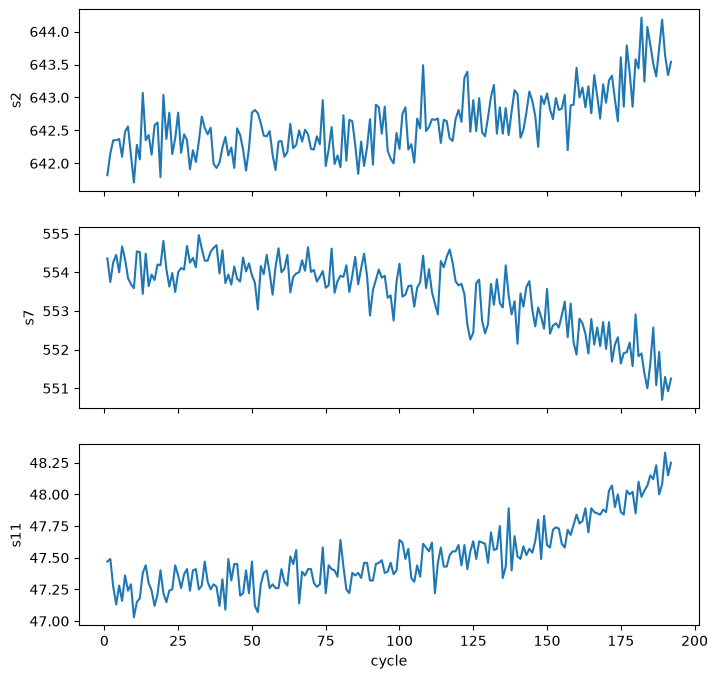

In [5]:
engine = train[train["unit"] == 1]
fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
for ax, s in zip(axes, ["s2", "s7", "s11"]):
    ax.plot(engine["cycle"], engine[s])
    ax.set_ylabel(s)
axes[-1].set_xlabel("cycle")
plt.show()

In [6]:
print(train.describe().T["std"])

unit     2.922763e+01
cycle    6.888099e+01
op1      2.187313e-03
op2      2.930621e-04
op3      0.000000e+00
s1       0.000000e+00
s2       5.000533e-01
s3       6.131150e+00
s4       9.000605e+00
s5       5.329200e-15
s6       1.388985e-03
s7       8.850923e-01
s8       7.098548e-02
s9       2.208288e+01
s10      0.000000e+00
s11      2.670874e-01
s12      7.375534e-01
s13      7.191892e-02
s14      1.907618e+01
s15      3.750504e-02
s16      3.469531e-18
s17      1.548763e+00
s18      0.000000e+00
s19      0.000000e+00
s20      1.807464e-01
s21      1.082509e-01
Name: std, dtype: float64
